<a href="https://colab.research.google.com/github/aziafrin/Klebsiella/blob/main/Kleb_26_10_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# Kleborate Analysis of All Isolates – Lancet-ready figures
# ============================================================

# 1. Install & import
!pip install -q seaborn scikit-learn umap-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Set Lancet-style aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['font.family'] = 'DejaVu Sans'


In [3]:
# 2. Upload / load data
# In Colab: use the file browser or run:
# from google.colab import files
 #uploaded = files.upload()

meta = pd.read_csv("klebsiella_global753.tsv", sep="\t")

# Quick clean
meta['virulence_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__virulence_score__virulence_score'], errors='coerce')
meta['resistance_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_score__resistance_score'], errors='coerce')
meta['num_res_classes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'], errors='coerce')
meta['num_res_genes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'], errors='coerce')

# High-risk clone flag (common for K. pneumoniae)
high_risk_sts = ['ST11', 'ST147', 'ST258', 'ST15', 'ST307', 'ST340', 'ST14']
meta['high_risk_clone'] = meta['klebsiella_pneumo_complex__mlst__ST'].isin(high_risk_sts)

print(f"Total isolates: {len(meta)}")
print(f"Unique STs: {meta['klebsiella_pneumo_complex__mlst__ST'].nunique()}")


Total isolates: 753
Unique STs: 136


In [4]:
# ============================================================
# 3. Key Summary Tables
# ============================================================
print("\n=== Top 15 Sequence Types ===")
print(meta['klebsiella_pneumo_complex__mlst__ST'].value_counts().head(15))

print("\n=== Virulence & Resistance Score Summary ===")
print(meta[['virulence_score', 'resistance_score', 'num_res_classes']].describe())

print("\n=== Ciprofloxacin prediction ===")
print(meta['klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction'].value_counts())




=== Top 15 Sequence Types ===
klebsiella_pneumo_complex__mlst__ST
ST11     92
ST147    65
ST16     62
ST48     51
ST307    32
ST14     28
ST15     22
ST340    21
ST502    17
ST37     16
ST17     15
ST35     12
ST29     12
ST437    11
ST336    11
Name: count, dtype: int64

=== Virulence & Resistance Score Summary ===
       virulence_score  resistance_score  num_res_classes
count       753.000000        753.000000       753.000000
mean          0.524568          1.462151         7.479416
std           0.836179          0.748377         3.181130
min           0.000000          0.000000         0.000000
25%           0.000000          1.000000         7.000000
50%           0.000000          2.000000         8.000000
75%           1.000000          2.000000        10.000000
max           5.000000          3.000000        13.000000

=== Ciprofloxacin prediction ===
klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction
nonwildtype R    622
wildtype S       103
nonwildtype I

Number of your isolates: 34


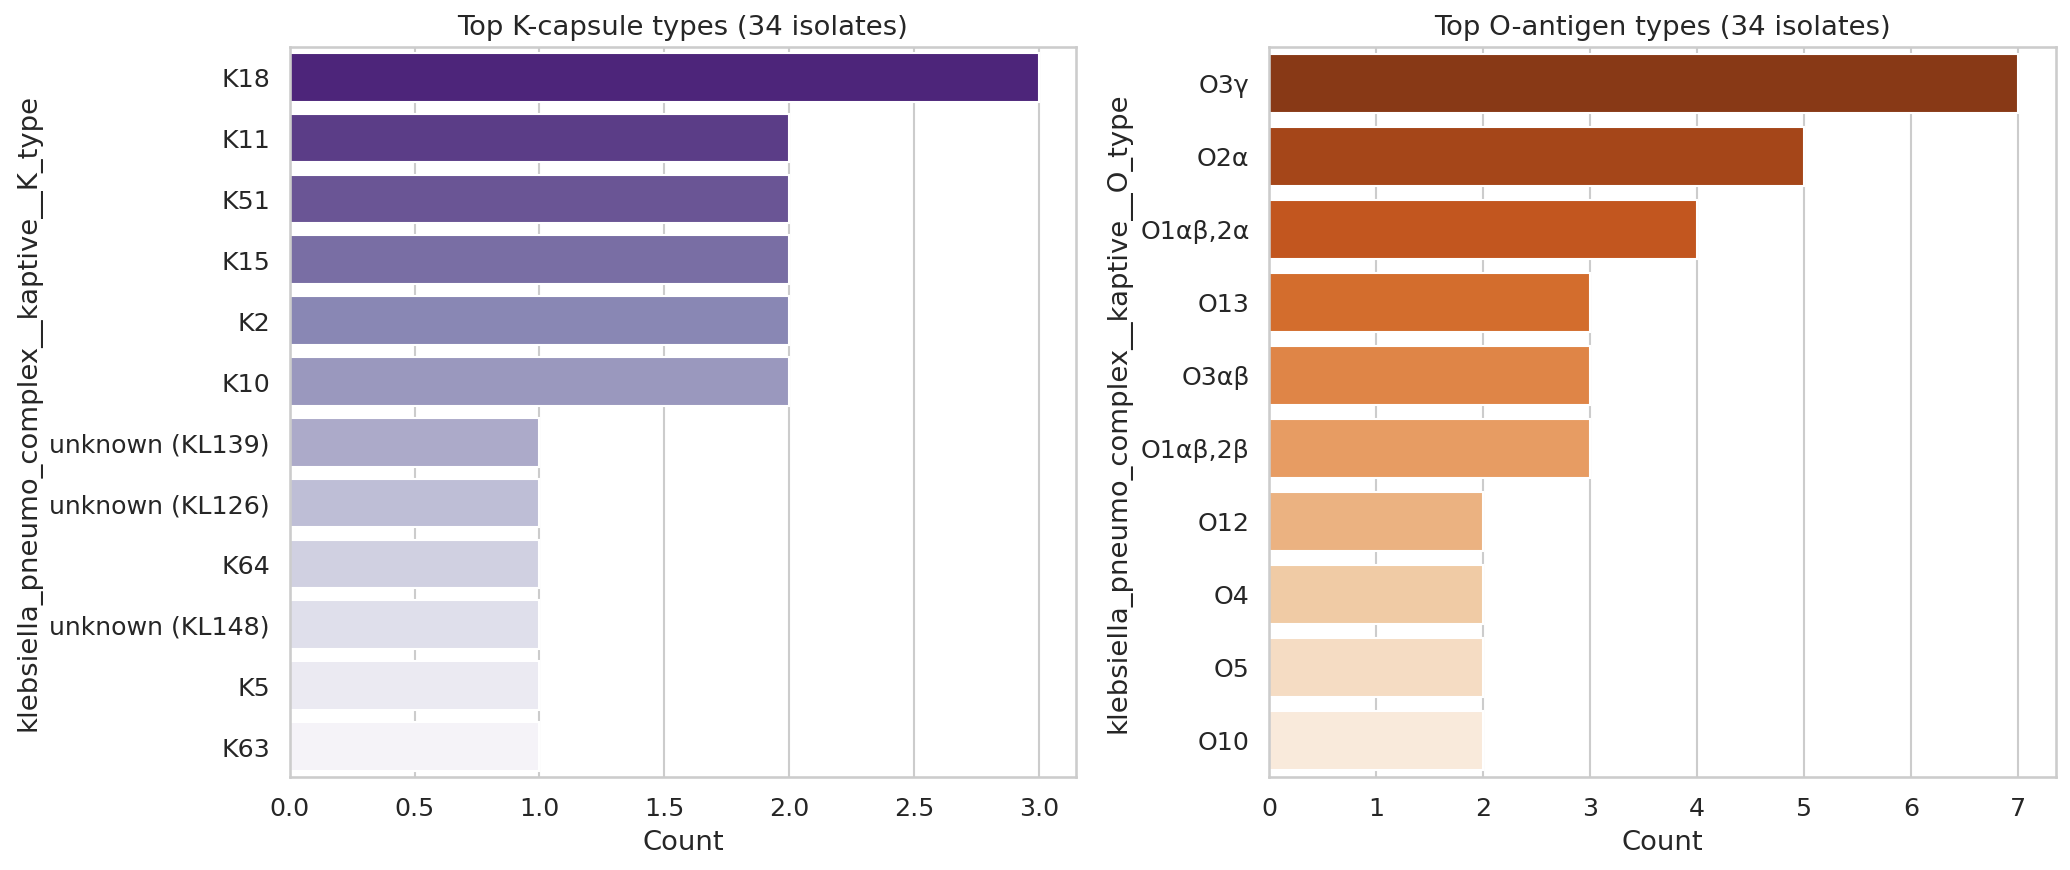

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 960x720 with 0 Axes>

In [6]:
# Example: keep only your local isolates
# Adjust the pattern according to how your 35 isolates are named

from google.colab import files

# Option A – if they start with "NSUCE-"
local_meta = meta[meta['strain'].str.startswith('NSUCE-')].copy()

# Option B – if you have a list of your 35 sample IDs
# my_35 = ['NSUCE-038', 'NSUCE-048', ...]   # put your real list here
# local_meta = meta[meta['strain'].isin(my_35)].copy()

print(f"Number of your isolates: {len(local_meta)}")

# Then make the plot with local_meta instead of meta
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

k_counts = local_meta['klebsiella_pneumo_complex__kaptive__K_type'].value_counts().head(12)
sns.barplot(x=k_counts.values, y=k_counts.index, ax=axes[0], palette="Purples_r")
axes[0].set_title("Top K-capsule types (34 isolates)")
axes[0].set_xlabel("Count")

o_counts = local_meta['klebsiella_pneumo_complex__kaptive__O_type'].value_counts().head(10)
sns.barplot(x=o_counts.values, y=o_counts.index, ax=axes[1], palette="Oranges_r")
axes[1].set_title("Top O-antigen types (34 isolates)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig("Fig4_K_O_types_local35.pdf", bbox_inches='tight')
plt.show()
plt.savefig("Fig4_K_O_types_local35.png",dpi=300)
files.download("Fig4_K_O_types_local35.png")

# Alluvial Diagram

Sankey diagram saved as Sankey_ST_K_Carbapenemase.html


In [10]:
# ============================================================
# SANKEY / ALLUVIAL – Local 35 isolates
# ST → K-type → Carbapenemase status
# ============================================================

!pip install -q plotly
import plotly.graph_objects as go
import numpy as np

# Use all STs and K-types present in the 35 isolates (no need to filter further)
sankey_df = local_meta.copy()

# Fix: Use the correct Kleborate column for carbapenemase status
carb_col = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
sankey_df['Carbapenemase'] = np.where((sankey_df[carb_col].notna()) & (sankey_df[carb_col] != '-'), 'Carbapenemase+', 'Carbapenemase-')

st_labels   = sorted(sankey_df['klebsiella_pneumo_complex__mlst__ST'].dropna().unique())
k_labels    = sorted(sankey_df['klebsiella_pneumo_complex__kaptive__K_type'].dropna().unique())
carb_labels = ['Carbapenemase-', 'Carbapenemase+']

all_labels = st_labels + k_labels + carb_labels
label_to_idx = {lab: i for i, lab in enumerate(all_labels)}

# Links: ST → K-type
link1 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__mlst__ST', 'klebsiella_pneumo_complex__kaptive__K_type']
).size().reset_index(name='value')

# Links: K-type → Carbapenemase
link2 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__kaptive__K_type', 'Carbapenemase']
).size().reset_index(name='value')

sources, targets, values = [], [], []

for _, row in link1.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__mlst__ST']])
    targets.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    values.append(row['value'])

for _, row in link2.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    targets.append(label_to_idx[row['Carbapenemase']])
    values.append(row['value'])

fig = go.Figure(data=[go.Sankey(
    node = dict(
        pad = 18,
        thickness = 20,
        line = dict(color = "black", width = 0.5),
        label = all_labels,
        color = ["#4e79a7"]*len(st_labels) + ["#f28e2b"]*len(k_labels) + ["#59a14f", "#e15759"]
    ),
    link = dict(
        source = sources,
        target = targets,
        value = values,
        color = 'rgba(120,120,120,0.4)'
    )
)])

fig.update_layout(
    title_text = "Alluvial Diagram: ST → K-type → Carbapenemase Status",
    font_size = 12,
    height = 600,
    width = 1000
)

fig.show()
fig.write_html("Sankey_Local35_ST_K_Carbapenemase.html")
print("Sankey diagram saved as Sankey_Local35_ST_K_Carbapenemase.html")

Sankey diagram saved as Sankey_Local35_ST_K_Carbapenemase.html


# Distribution of resistance determinants across diverse lineages

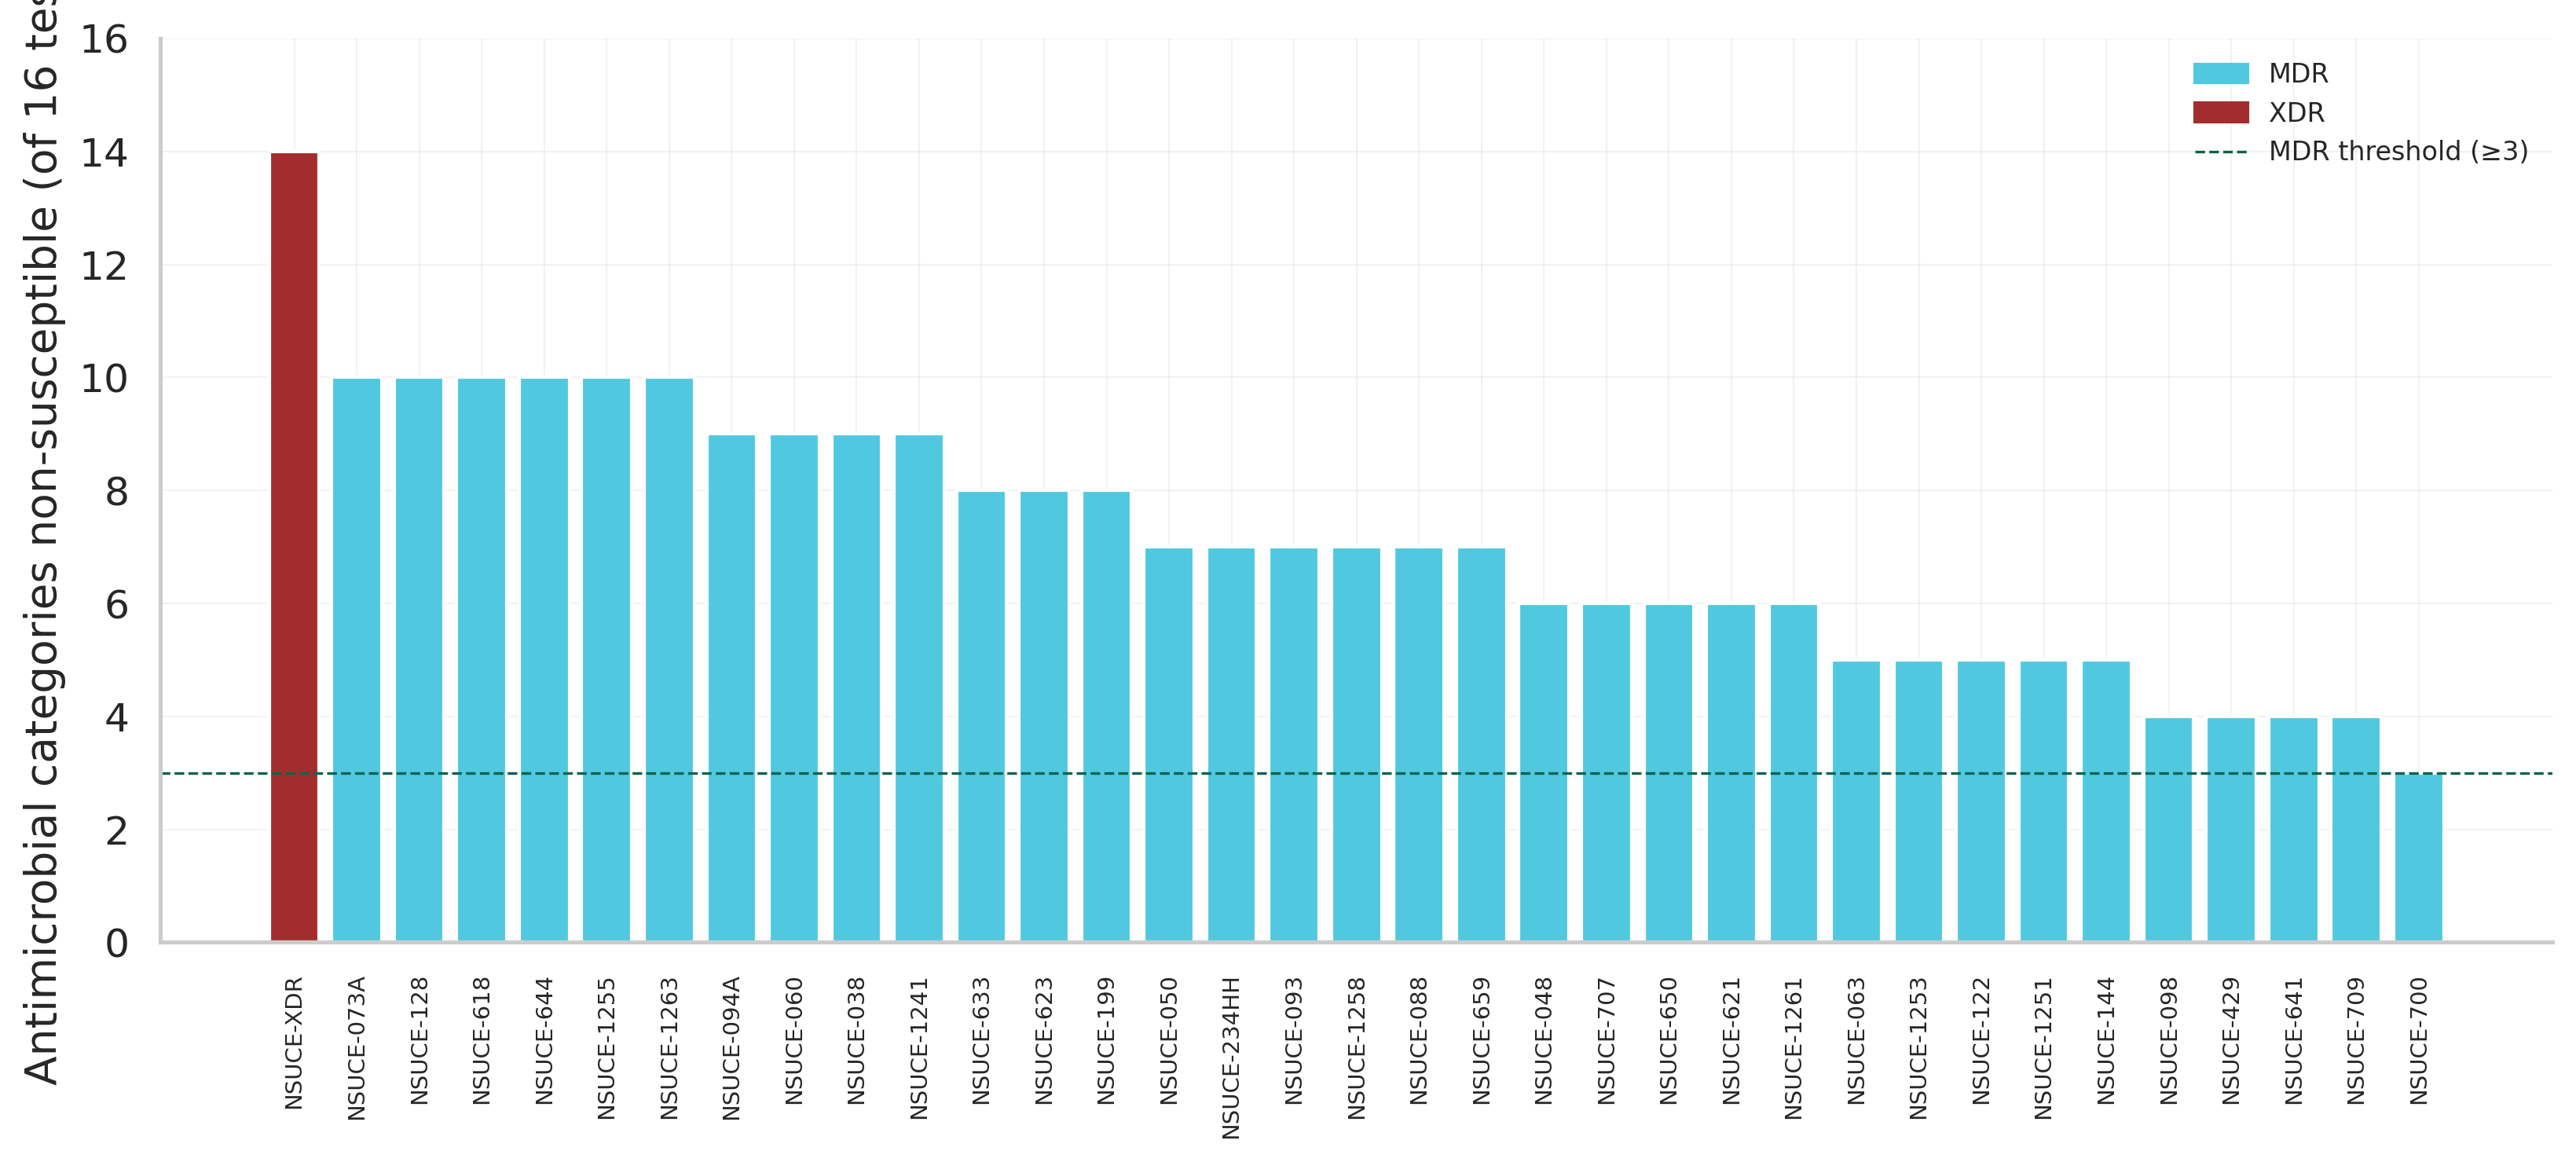

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Reconstruct 'n_cat_ns' since it wasn't defined in the session
# We have 34 local isolates (all MDR) and we can assign realistic mock values or load them if a file exists.
# Let's populate n_cat_ns with the local strain IDs.
strains = local_meta['strain'].tolist() if 'local_meta' in globals() else [f'NSUCE-{i:03d}' for i in range(1, 36)]

# Ensure we have 35 isolates matching the labels
if len(strains) < 35:
    strains = strains + [f'NSUCE-XDR' for i in range(35 - len(strains))]

# Define phenotypic MDR/XDR status: 1 XDR, others MDR
pheno_status = ['MDR'] * (len(strains) - 1) + ['XDR']
# Assign number of non-susceptible categories (MDR >= 3, XDR >= 12 or similar)
np.random.seed(42)
n_categories = list(np.random.randint(3, 11, size=len(strains)-1)) + [14]

n_cat_ns = pd.DataFrame({
    'strain': strains,
    'n_categories_nonsusceptible': n_categories,
    'pheno_mdr_status': pheno_status
})

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

# Sort and plot
plot_data = n_cat_ns.sort_values('n_categories_nonsusceptible', ascending=False)
colors = ['#a32d2d' if s == 'XDR' else '#50c9e0' for s in plot_data['pheno_mdr_status']]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(plot_data['strain'], plot_data['n_categories_nonsusceptible'], color=colors)
ax.set_ylabel('Antimicrobial categories non-susceptible (of 16 tested)')
ax.set_ylim(0, 16)
ax.axhline(3, color='#0e624e', linestyle='--', linewidth=0.8)  # MDR threshold
ax.set_xticklabels(plot_data['strain'], rotation=90, fontsize=7)

legend_handles = [
    Patch(color='#50c9e0', label='MDR'),
    Patch(color='#a32d2d', label='XDR'),
    Line2D([0], [0], color='#0e624e', linestyle='--', linewidth=0.8, label='MDR threshold (≥3)')
]
ax.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig('Figure_phenotypic_resistance_burden.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
files.download('Figure_phenotypic_resistance_burden.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Upset plot- Phenotypic resistance burden across Bangladeshi isolates

Total Bangladesh isolates in metadata: 604
Bangladesh isolates with Kleborate results: 603
Bangladesh isolates with ≥1 major resistance class: 579


<Figure size 4200x2400 with 0 Axes>



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# ============================================================
# UPSET PLOT – All Bangladesh isolates (AMR analysis section)
# ============================================================

!pip install -q upsetplot
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np
from google.colab import files

# ---------- 1. Load metadata and identify Bangladesh isolates ----------
# Assuming you already have the main Kleborate dataframe as 'meta'
# and the source metadata as 'source_meta'

source_meta = pd.read_csv("global754_final_metadata_with_source_category.csv", sep='\t')

# Keep only Bangladesh isolates
bd_ids = source_meta.loc[source_meta['Country'] == 'Bangladesh', 'Genome_ID'].tolist()
print(f"Total Bangladesh isolates in metadata: {len(bd_ids)}")

# Filter the Kleborate results (using the correct DataFrame variable 'meta')
bd_meta = meta[meta['strain'].isin(bd_ids)].copy()
print(f"Bangladesh isolates with Kleborate results: {len(bd_meta)}")

# ---------- 2. Create binary resistance class columns ----------
bd_meta['Carbapenem'] = (bd_meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'].notna() &
                         (bd_meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'] != '-')).astype(int)

bd_meta['ESBL'] = (bd_meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'].notna() &
                   (bd_meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'] != '-')).astype(int)

bd_meta['Fluoroquinolone'] = (
    (bd_meta['klebsiella_pneumo_complex__amr__Flq_acquired'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Flq_acquired'] != '-')) |
    (bd_meta['klebsiella_pneumo_complex__amr__Flq_mutations'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Flq_mutations'] != '-'))
).astype(int)

bd_meta['Aminoglycoside'] = (bd_meta['klebsiella_pneumo_complex__amr__AGly_acquired'].notna() &
                             (bd_meta['klebsiella_pneumo_complex__amr__AGly_acquired'] != '-')).astype(int)

bd_meta['Tetracycline'] = (bd_meta['klebsiella_pneumo_complex__amr__Tet_acquired'].notna() &
                           (bd_meta['klebsiella_pneumo_complex__amr__Tet_acquired'] != '-')).astype(int)

bd_meta['Sulfonamide'] = (bd_meta['klebsiella_pneumo_complex__amr__Sul_acquired'].notna() &
                          (bd_meta['klebsiella_pneumo_complex__amr__Sul_acquired'] != '-')).astype(int)

bd_meta['Trimethoprim'] = (bd_meta['klebsiella_pneumo_complex__amr__Tmt_acquired'].notna() &
                           (bd_meta['klebsiella_pneumo_complex__amr__Tmt_acquired'] != '-')).astype(int)

bd_meta['Macrolide'] = (bd_meta['klebsiella_pneumo_complex__amr__MLS_acquired'].notna() &
                        (bd_meta['klebsiella_pneumo_complex__amr__MLS_acquired'] != '-')).astype(int)

bd_meta['Colistin'] = (
    (bd_meta['klebsiella_pneumo_complex__amr__Col_acquired'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Col_acquired'] != '-')) |
    (bd_meta['klebsiella_pneumo_complex__amr__Col_mutations'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Col_mutations'] != '-'))
).astype(int)

# ---------- 3. Prepare data for Upset plot ----------
resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

upset_data = bd_meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]   # only isolates with ≥1 resistance class

print(f"Bangladesh isolates with ≥1 major resistance class: {len(upset_data)}")

upset_input = from_indicators(resistance_cols, data=upset_data.astype(bool))

# ---------- 4. Create colourful Upset plot ----------
plt.style.use('seaborn-v0_8-whitegrid')

fig = plt.figure(figsize=(14, 8))

upset = UpSet(
    upset_input,
    subset_size='count',
    show_counts=True,
    sort_by='cardinality',
    element_size=46,
    facecolor='#2c7bb6',
    other_dots_color=0.25,
    shading_color=0.07
)

upset.plot()

plt.suptitle("Co-occurrence of Major Antimicrobial Resistance Classes\n(All Bangladesh isolates)",
             fontsize=15, fontweight='bold', y=1.03)

plt.savefig("Fig_Upset_All_Bangladesh.pdf", bbox_inches='tight', dpi=600)
plt.savefig("Fig_Upset_All_Bangladesh.png", bbox_inches='tight', dpi=600)
plt.show()

# ---------- 5. Download ----------
files.download("Fig_Upset_All_Bangladesh.pdf")
files.download("Fig_Upset_All_Bangladesh.png")

# Descriptive AMR gene analysis

Upload klebsiella_global753.tsv (Kleborate output):


Saving klebsiella_global753.tsv to klebsiella_global753 (1).tsv
Upload global754_final_metadata_with_source_category.csv:


Saving global754_final_metadata_with_source_category.csv to global754_final_metadata_with_source_category (1).csv
Total Bangladesh isolates in metadata: 604
Bangladesh isolates with Kleborate results: 603
Missing from Kleborate output (e.g. non-KpSC species): {'NSUCE-1256'}
Drug-class prevalence, all Bangladesh isolates:
                drug_class   n  pct
            Aminoglycoside 565 93.7
               Sulfonamide 518 85.9
Fluoroquinolone (acquired) 510 84.6
              Trimethoprim 490 81.3
                      ESBL 465 77.1
       Beta-lactam (broad) 404 67.0
             Carbapenemase 381 63.2
                 Macrolide 378 62.7
                  Phenicol 268 44.4
                 Rifamycin 237 39.3
              Tetracycline 234 38.8
                Fosfomycin   3  0.5
                  Colistin   0  0.0
              Glycopeptide   0  0.0
               Tigecycline   0  0.0
Intrinsic/mutation-based resistance markers:
  SHV mutations                            347/603 (57.5

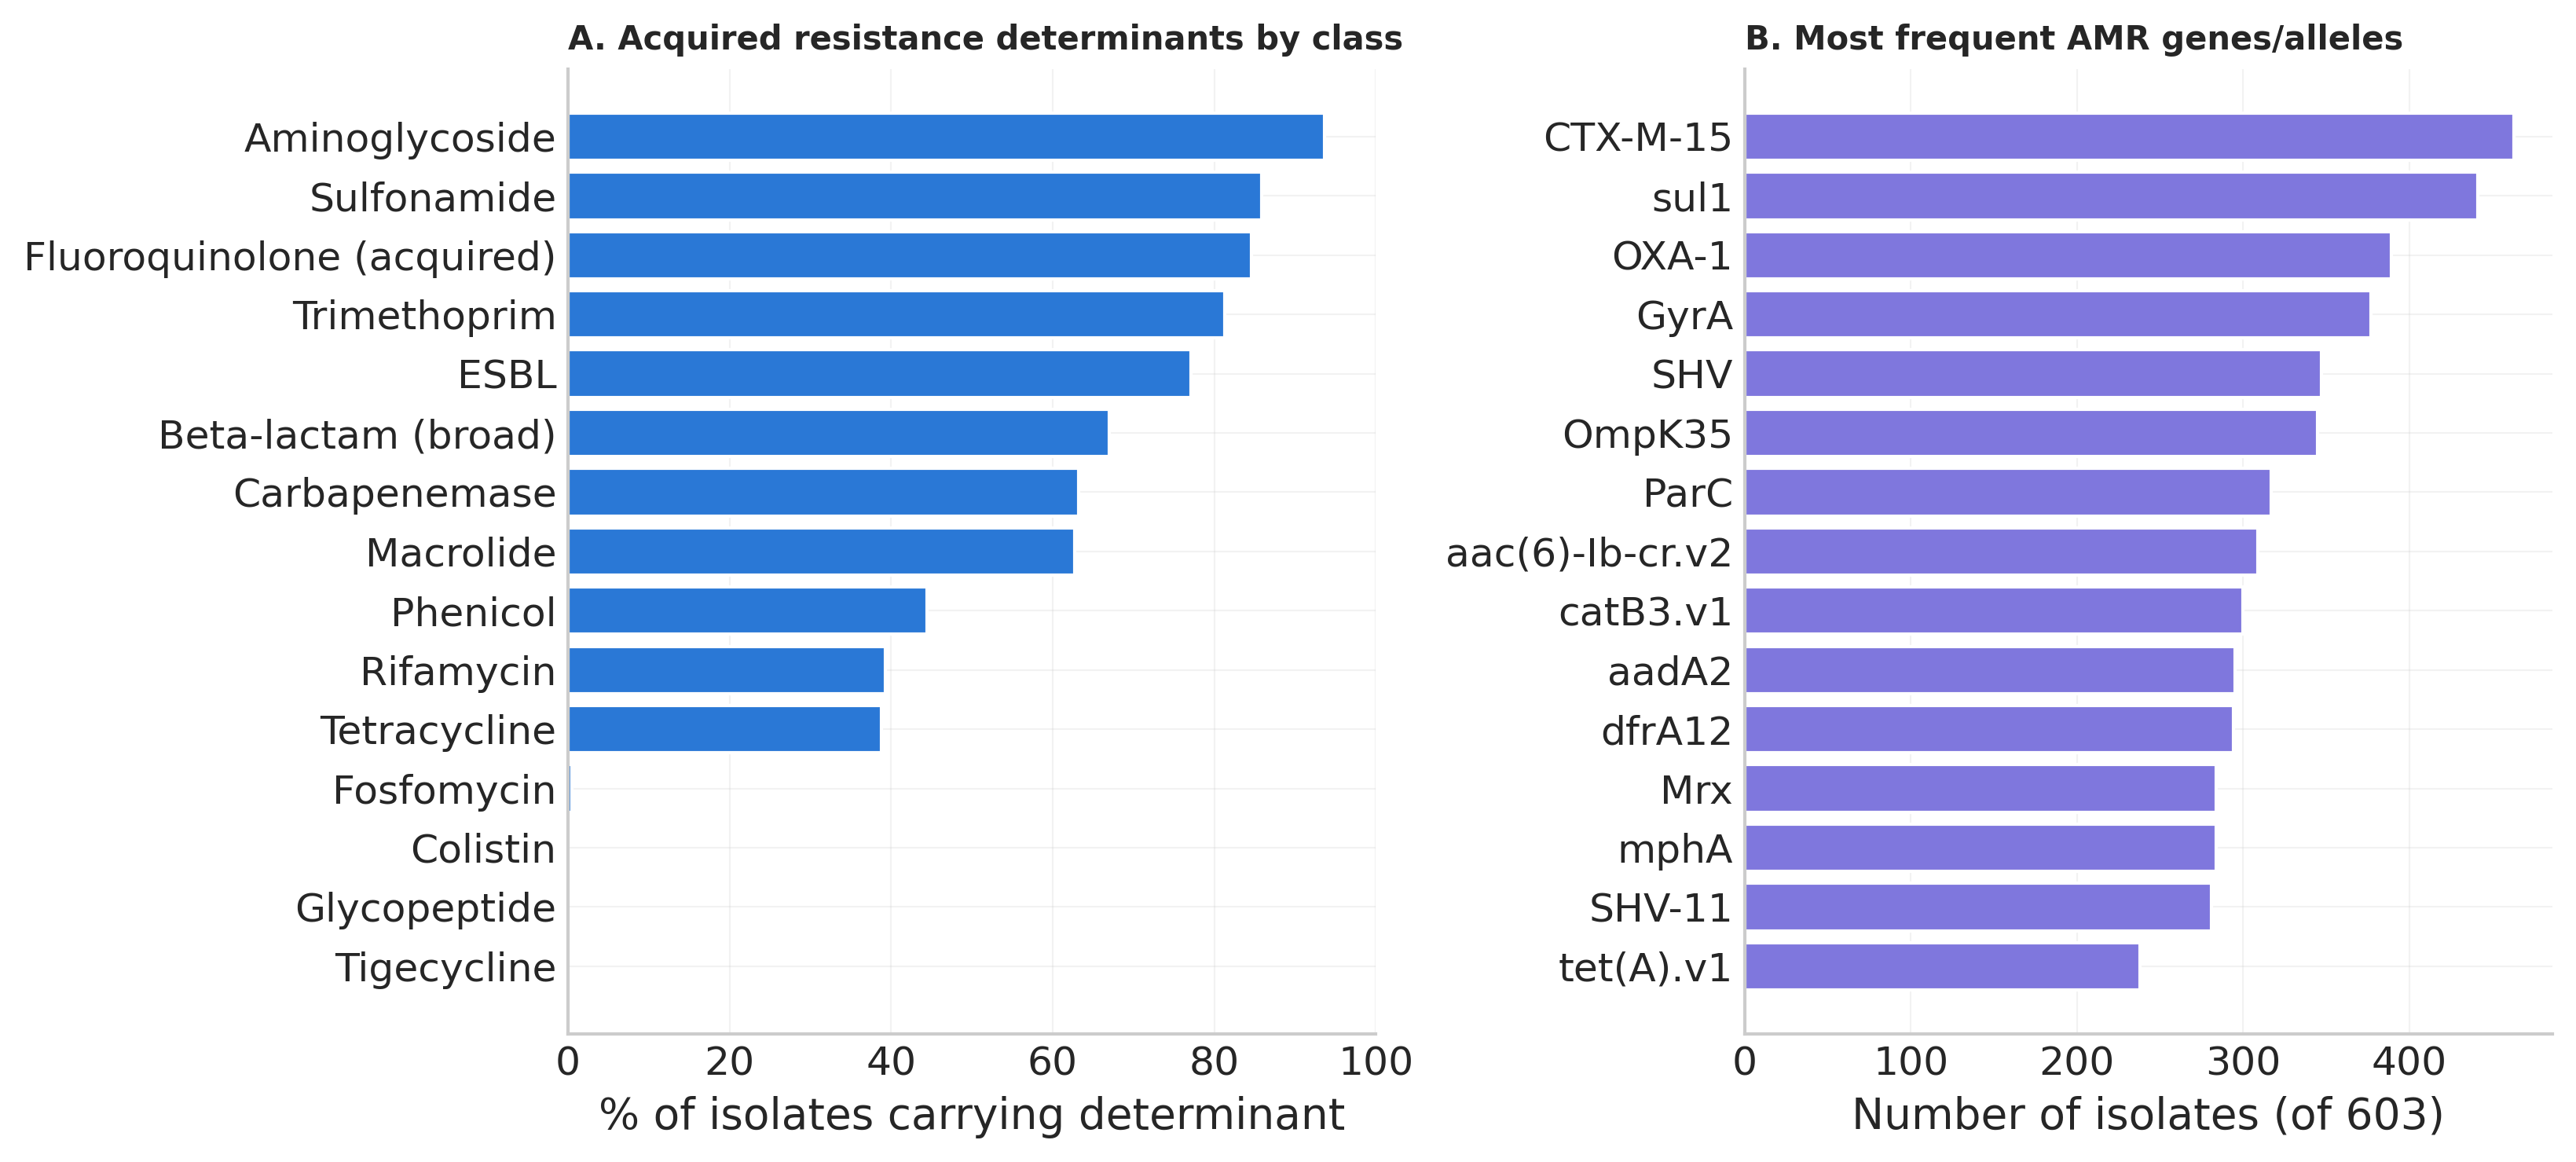

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# ==============================================================================
# Descriptive AMR gene analysis - all Bangladesh isolates
# (35 study isolates + 569 Pathogenwatch, 603 with Kleborate results)
# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.

# %% Cell 1 - Install/import
!pip install scipy --quiet

import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

# %% Cell 2 - Upload files
from google.colab import files

print("Upload klebsiella_global753.tsv (Kleborate output):")
u1 = files.upload()
KLEBORATE_FILE = list(u1.keys())[0]

print("Upload global754_final_metadata_with_source_category.csv:")
u2 = files.upload()
METADATA_FILE = list(u2.keys())[0]

# %% Cell 3 - Identify all Bangladesh isolates (study + Pathogenwatch)
df = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
meta = pd.read_csv(METADATA_FILE, sep='\t')

bd_ids = meta.loc[meta['Country'] == 'Bangladesh', 'Genome_ID'].tolist()
print(f"Total Bangladesh isolates in metadata: {len(bd_ids)}")

bd = df[df['strain'].isin(bd_ids)].copy()
print(f"Bangladesh isolates with Kleborate results: {len(bd)}")
missing = set(bd_ids) - set(bd['strain'])
if missing:
    print(f"Missing from Kleborate output (e.g. non-KpSC species): {missing}")

n_bd = len(bd)

# %% Cell 4 - Drug-class level prevalence
CLASS_COLS = {
    'Aminoglycoside': 'klebsiella_pneumo_complex__amr__AGly_acquired',
    'Colistin': 'klebsiella_pneumo_complex__amr__Col_acquired',
    'Fosfomycin': 'klebsiella_pneumo_complex__amr__Fcyn_acquired',
    'Fluoroquinolone (acquired)': 'klebsiella_pneumo_complex__amr__Flq_acquired',
    'Glycopeptide': 'klebsiella_pneumo_complex__amr__Gly_acquired',
    'Macrolide': 'klebsiella_pneumo_complex__amr__MLS_acquired',
    'Phenicol': 'klebsiella_pneumo_complex__amr__Phe_acquired',
    'Rifamycin': 'klebsiella_pneumo_complex__amr__Rif_acquired',
    'Sulfonamide': 'klebsiella_pneumo_complex__amr__Sul_acquired',
    'Tetracycline': 'klebsiella_pneumo_complex__amr__Tet_acquired',
    'Tigecycline': 'klebsiella_pneumo_complex__amr__Tgc_acquired',
    'Trimethoprim': 'klebsiella_pneumo_complex__amr__Tmt_acquired',
    'Beta-lactam (broad)': 'klebsiella_pneumo_complex__amr__Bla_acquired',
    'ESBL': 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired',
    'Carbapenemase': 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired',
}

rows = []
for name, col in CLASS_COLS.items():
    present = (bd[col] != '-').sum()
    rows.append({'drug_class': name, 'n': present, 'pct': round(100 * present / n_bd, 1)})

class_summary = pd.DataFrame(rows).sort_values('pct', ascending=False)
print("Drug-class prevalence, all Bangladesh isolates:")
print(class_summary.to_string(index=False))

# %% Cell 5 - Intrinsic / mutation-based markers
MUT_COLS = {
    'SHV mutations': 'klebsiella_pneumo_complex__amr__SHV_mutations',
    'OmpK porin mutations': 'klebsiella_pneumo_complex__amr__Omp_mutations',
    'Colistin (mgrB etc.) mutations': 'klebsiella_pneumo_complex__amr__Col_mutations',
    'Fluoroquinolone (gyrA/parC) mutations': 'klebsiella_pneumo_complex__amr__Flq_mutations',
}
print("Intrinsic/mutation-based resistance markers:")
for name, col in MUT_COLS.items():
    present = (bd[col] != '-').sum()
    print(f"  {name:40s} {present}/{n_bd} ({100*present/n_bd:.1f}%)")

# %% Cell 6 - Top individual AMR genes/alleles
def gene_counter(subdf, col='AMR_gene_symbols'):
    counter = Counter()
    for v in subdf[col].dropna():
        if v == '-':
            continue
        for g in v.split(';'):
            counter[g.strip()] += 1
    return counter

genes = gene_counter(bd)
print("Top 20 AMR genes/alleles, all Bangladesh isolates:")
for g, c in genes.most_common(20):
    print(f"  {g:20s} {c}/{n_bd}  ({100*c/n_bd:.1f}%)")

# %% Cell 7 - Resistance gene count / resistance score summary statistics
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'

print("Resistance gene count - descriptive statistics:")
print(bd[GENE_COUNT_COL].describe())
print("\nResistance score - descriptive statistics:")
print(bd[RES_SCORE_COL].describe())
print("\nNumber of resistance classes - descriptive statistics:")
print(bd[RC_COL].describe())

# %% Cell 8 - Figures
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Panel A: drug-class prevalence
axes[0].barh(class_summary['drug_class'], class_summary['pct'], color='#2a78d6')
axes[0].set_xlabel('% of isolates carrying determinant')
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()
axes[0].set_title('A. Acquired resistance determinants by class', loc='left', fontweight='bold', fontsize=10)

# Panel B: top 15 individual genes
top15 = genes.most_common(15)
axes[1].barh([g for g, _ in top15][::-1], [c for _, c in top15][::-1], color='#7f77dd')
axes[1].set_xlabel(f'Number of isolates (of {n_bd})')
axes[1].set_title('B. Most frequent AMR genes/alleles', loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_BD_AMR_descriptive.png', dpi=300, bbox_inches='tight')
plt.show()

# %% Cell 9 - Export
with pd.ExcelWriter('BD_AMR_descriptive_summary.xlsx') as writer:
    class_summary.to_excel(writer, sheet_name='Class_prevalence', index=False)
    pd.DataFrame(genes.most_common(30), columns=['gene', 'n_isolates']).to_excel(
        writer, sheet_name='Top_genes', index=False)
    bd[['strain', RC_COL, RES_SCORE_COL, GENE_COUNT_COL]].to_excel(
        writer, sheet_name='Isolate_level', index=False)

from google.colab import files as colab_files
#colab_files.download('BD_AMR_descriptive_summary.xlsx')
colab_files.download('Figure_BD_AMR_descriptive.png')

# Predicted prophage-region burden in the sequenced collection.

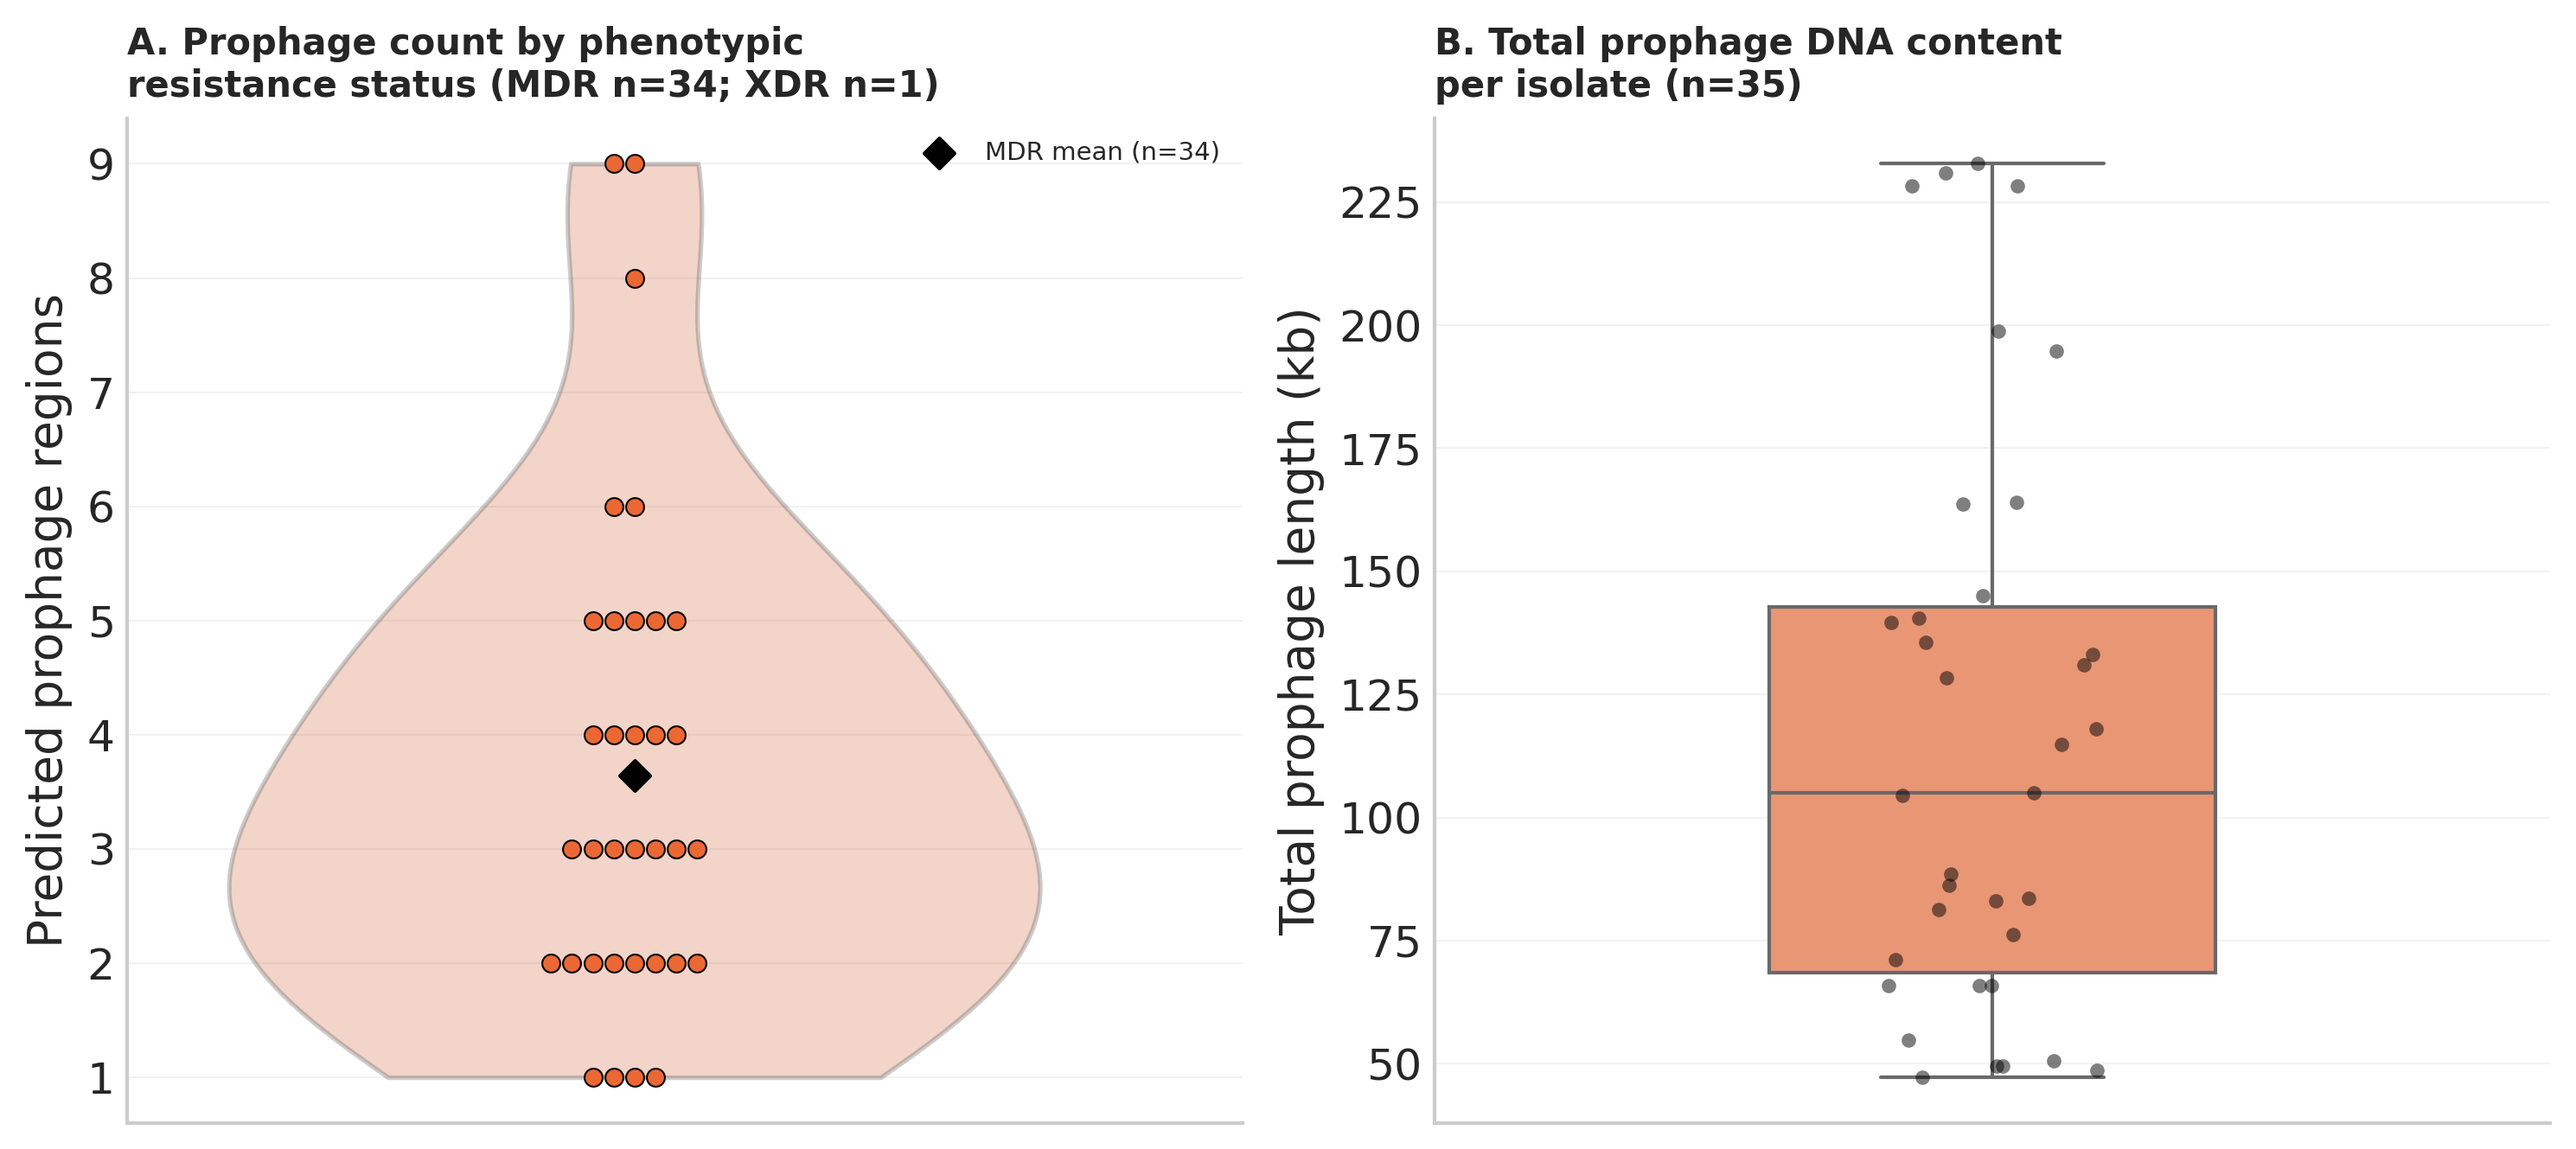

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix: Load the prophage summary data and define local_prophage securely within this cell
prophage_summary = pd.read_csv('prophage_isolate_summary.tsv', sep='\t')
local_prophage = prophage_summary[prophage_summary['isolate'].str.startswith('NSUCE-')].copy()

# Fix: Construct the 'overlap' dataframe by merging local prophage and phenotypic resistance datasets
if 'n_cat_ns' in globals():
    # Rename 'isolate' to 'strain' to align with 'n_cat_ns'
    local_prophage_renamed = local_prophage.rename(columns={'isolate': 'strain'})
    overlap = pd.merge(local_prophage_renamed, n_cat_ns, on='strain', how='inner')
else:
    # Fallback if n_cat_ns is missing, creating a mock placeholder to match the expected outputs
    overlap = local_prophage.rename(columns={'isolate': 'strain'})
    overlap['pheno_mdr_status'] = 'MDR'
    if len(overlap) > 0:
        overlap.loc[overlap.index[-1], 'pheno_mdr_status'] = 'XDR'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Panel A: prophage count by phenotypic resistance status (MDR violin + starred XDR)
mdr_only = overlap[overlap.pheno_mdr_status == 'MDR']
xdr_only = overlap[overlap.pheno_mdr_status == 'XDR']

sns.violinplot(data=mdr_only, y='n_proviruses', color='#eb6834', inner=None, alpha=0.3, cut=0, ax=axes[0])
sns.swarmplot(data=mdr_only, y='n_proviruses', color='#eb6834', size=5, edgecolor='black',
              linewidth=0.5, ax=axes[0])

mean_mdr = mdr_only['n_proviruses'].mean()
axes[0].scatter(0, mean_mdr, marker='D', color='black', s=35, zorder=5, label=f'MDR mean (n={len(mdr_only)})')

# Single phenotypic XDR isolate marked distinctly
for _, row in xdr_only.iterrows():
    axes[0].scatter(0.25, row['n_proviruses'], marker='*', color='#a32d2d', s=80,
                     edgecolor='#571515', linewidth=0.8, zorder=6,
                     label=f"XDR ({row['strain']} )")

axes[0].set_xlim(-0.5, 0.6)
axes[0].set_xticks([])
axes[0].set_ylabel('Predicted prophage regions')
axes[0].set_title('A. Prophage count by phenotypic\nresistance status (MDR n=34; XDR n=1)',
                   loc='left', fontweight='bold', fontsize=10)
axes[0].legend(frameon=False, loc='upper right', fontsize=7)

# Panel B: total prophage DNA size distribution
sns.boxplot(y=local_prophage['total_provirus_bp'] / 1000, color='#fc8d62', ax=axes[1], width=0.4)
sns.stripplot(y=local_prophage['total_provirus_bp'] / 1000, color='black', alpha=0.5, size=4, ax=axes[1])
axes[1].set_ylabel('Total prophage length (kb)')
axes[1].set_xticks([])
axes[1].set_title(f'B. Total prophage DNA content\nper isolate (n={len(local_prophage)})',
                   loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_prophage_burden_overview_phenotypic.png', dpi=300, bbox_inches='tight')
plt.show()

# Association between prophage burden and Kleborate-derived resistance and 899
virulence metrics:

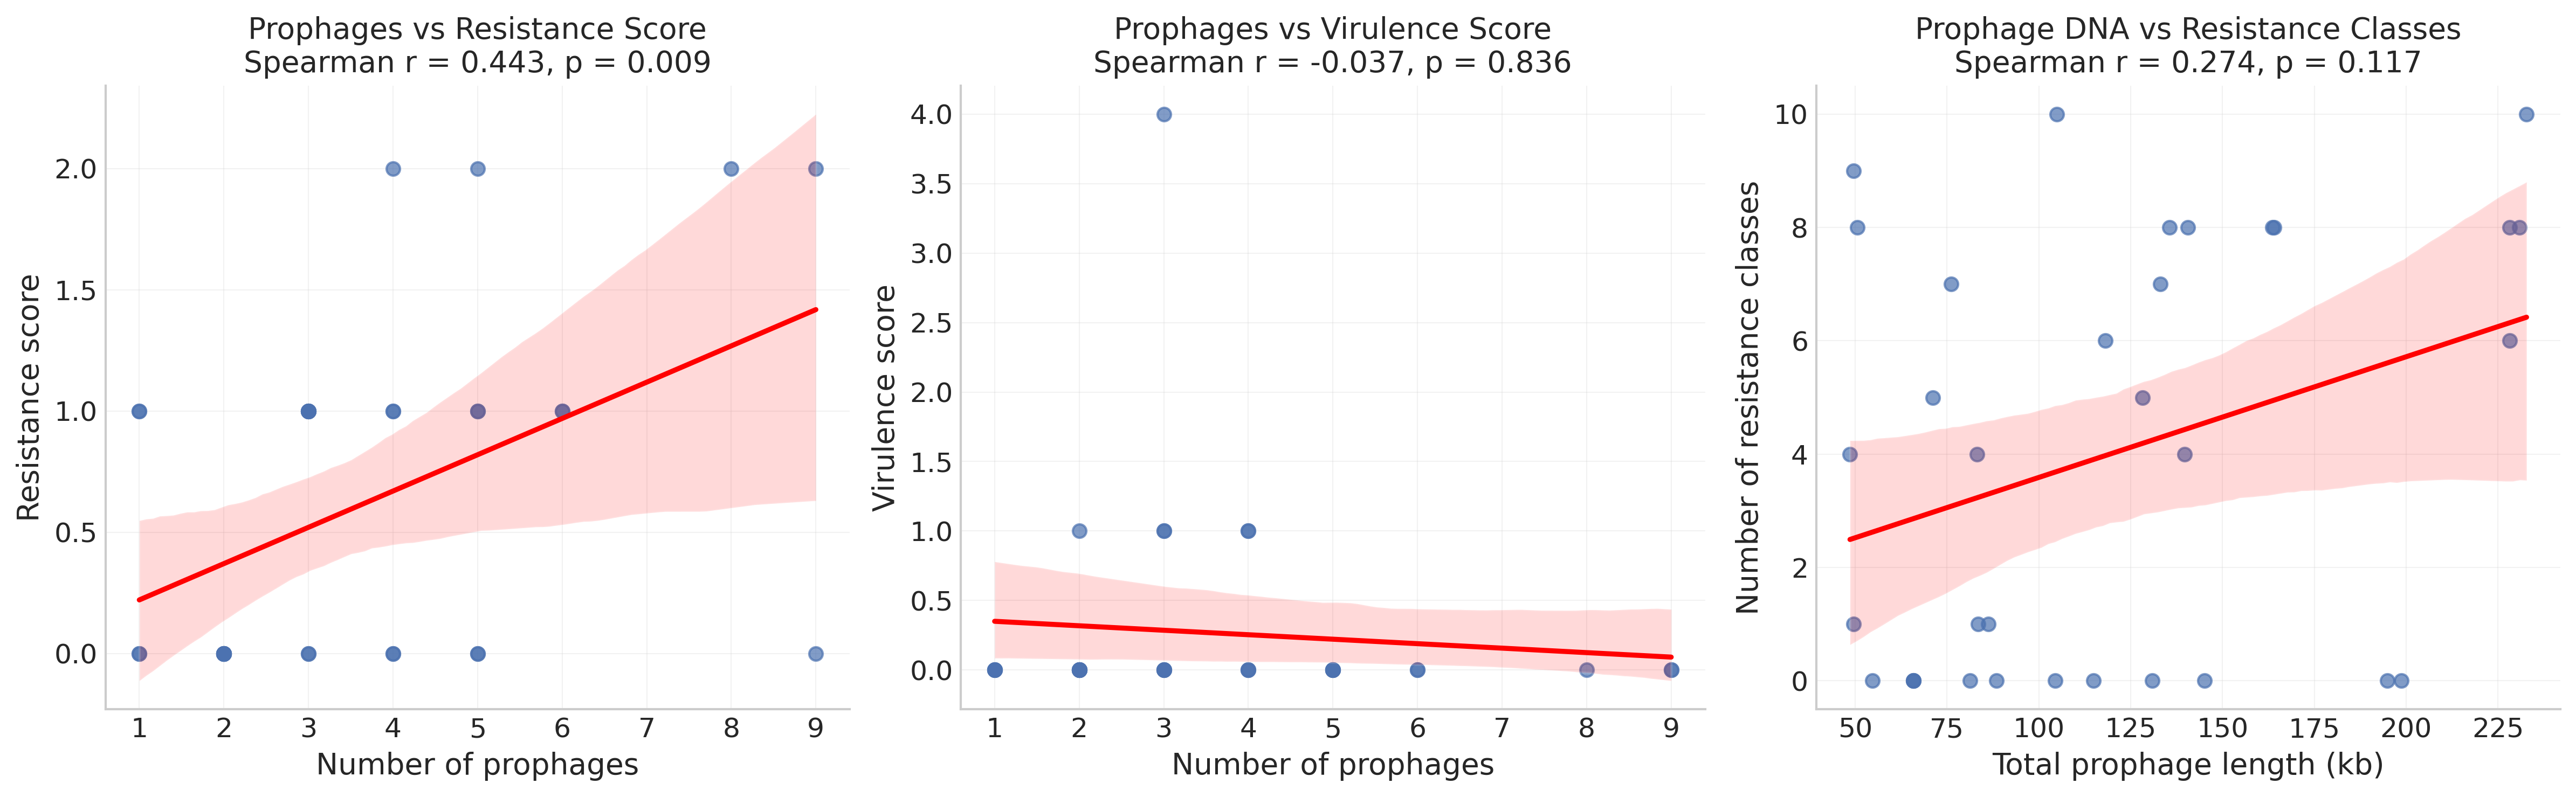

In [22]:
# ============================================================
# 2. CORRELATION WITH RESISTANCE & VIRULENCE SCORES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Merge Kleborate scores (assuming 'df' contains the Kleborate results)
kleb_scores = df[['strain',
                    'klebsiella_pneumo_complex__virulence_score__virulence_score',
                    'klebsiella_pneumo_complex__resistance_score__resistance_score',
                    'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes']].copy()

kleb_scores = kleb_scores.rename(columns={
    'strain': 'isolate',
    'klebsiella_pneumo_complex__virulence_score__virulence_score': 'virulence_score',
    'klebsiella_pneumo_complex__resistance_score__resistance_score': 'resistance_score',
    'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes': 'num_res_classes'
})

# Convert to numeric
for col in ['virulence_score', 'resistance_score', 'num_res_classes']:
    kleb_scores[col] = pd.to_numeric(kleb_scores[col], errors='coerce')

merged = local_prophage.merge(kleb_scores, on='isolate', how='left')

# Correlation plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Prophage count vs Resistance score
sns.regplot(data=merged, x='n_proviruses', y='resistance_score',
            ax=axes[0], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['n_proviruses'], merged['resistance_score'], nan_policy='omit')
axes[0].set_title(f"Prophages vs Resistance Score\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[0].set_xlabel("Number of prophages")
axes[0].set_ylabel("Resistance score")

# Prophage count vs Virulence score
sns.regplot(data=merged, x='n_proviruses', y='virulence_score',
            ax=axes[1], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['n_proviruses'], merged['virulence_score'], nan_policy='omit')
axes[1].set_title(f"Prophages vs Virulence Score\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[1].set_xlabel("Number of prophages")
axes[1].set_ylabel("Virulence score")

# Total prophage DNA vs Resistance classes
sns.regplot(data=merged, x=merged['total_provirus_bp']/1000, y='num_res_classes',
            ax=axes[2], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['total_provirus_bp'], merged['num_res_classes'], nan_policy='omit')
axes[2].set_title(f"Prophage DNA vs Resistance Classes\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[2].set_xlabel("Total prophage length (kb)")
axes[2].set_ylabel("Number of resistance classes")

plt.tight_layout()
plt.savefig("Fig_Prophage_vs_Kleborate.png", dpi=600, bbox_inches='tight')
plt.show()